# 30DayMapChallenge – Day 4: My Data

Where do plastic surgeons cluster in Vienna?

For Day 4 of the #30DayMapChallenge, I explored the spatial distribution of physicians specializing in plastic surgery across Vienna. Using DBSCAN, a density-based spatial clustering algorithm, I identified four distinct clusters of medical practices. The map reveals a strong concentration of specialists in and around Vienna's central districts, while practices in the outer districts appear considerably more dispersed. Each color represents a separate spatial cluster, with grey dots indicating physicians not assigned to any cluster. This visualization highlights how specialized medical services tend to concentrate in particular urban areas rather than being evenly distributed across the city.

#30DayMapChallenge #Day4 #MyData #Vienna #SpatialAnalysis #DBSCAN #Python #GeoPandas #GIS #HealthcareGeography

In [17]:
import geopandas as gpd
from shapely.ops import unary_union
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN
from cycler import cycler

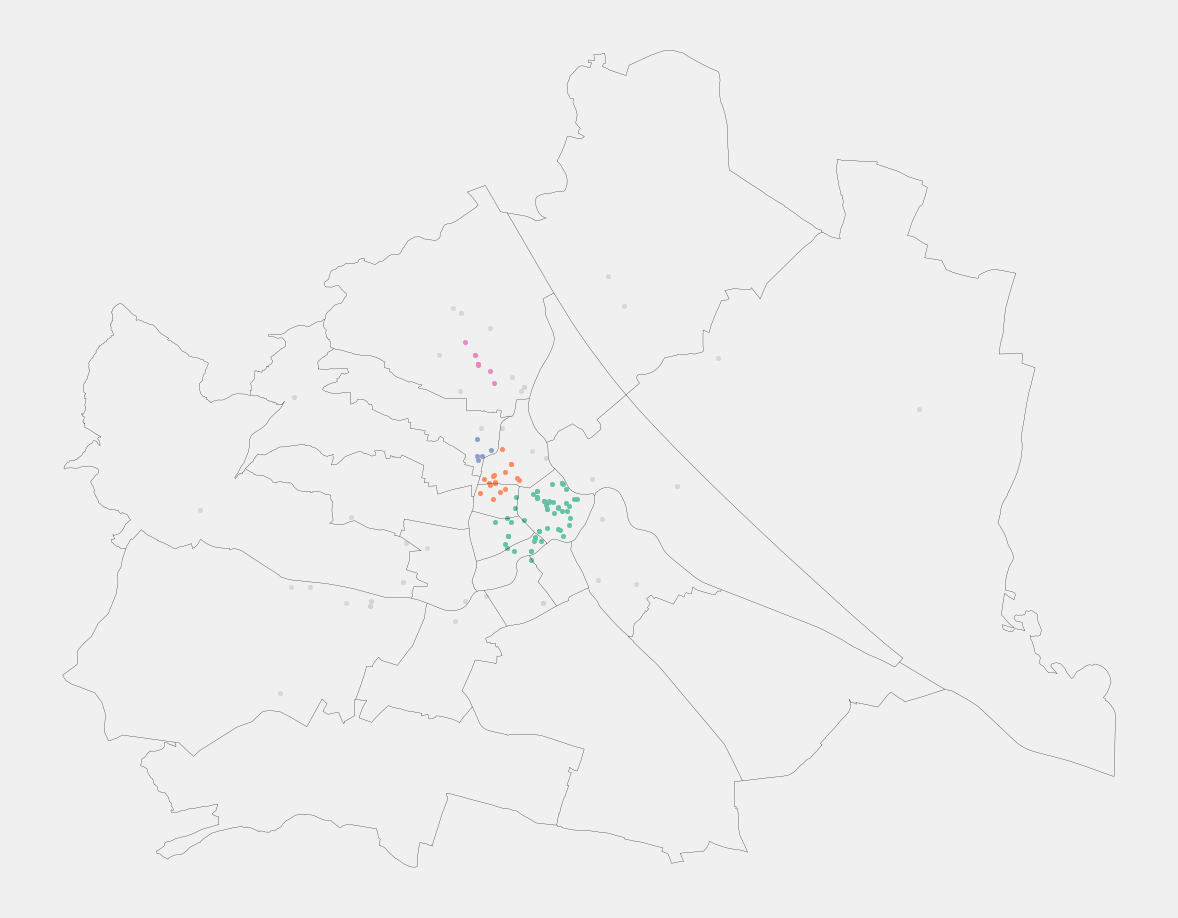

In [46]:
# GeoDataFrame mit Punkten
gdf = gpd.read_file("data/plastic_surgery.geojson")
districts = gpd.read_file("data/vienna_districts_lines.geojson")

# Metrisches Koordinatensystem
gdf = gdf.to_crs(epsg=31287)
districts = districts.to_crs(epsg=31287)

# Koordinaten extrahieren
coords = np.column_stack([
    gdf.geometry.x,
    gdf.geometry.y
])

# DBSCAN
db = DBSCAN(
    eps=500,  # maximaler Nachbarschaftsabstand: 200 Meter
    min_samples=5  # mindestens 5 Punkte für einen Kernpunkt
)

gdf["cluster"] = db.fit_predict(coords)

n_clusters = gdf.loc[gdf.cluster != -1, "cluster"].nunique()

fig, ax = plt.subplots(figsize=(12, 12))

districts.plot(ax=ax,
               color="black",
               linewidth=0.2
               )

gdf[gdf.cluster != -1].plot(
    ax=ax,
    column="cluster",
    categorical=True,
    cmap="Set2",
    markersize=10,
    legend=False
)

# noise
gdf[gdf.cluster == -1].plot(
    ax=ax,
    color="lightgrey",
    markersize=10,
    alpha=0.8
)

ax.set_axis_off()
plt.tight_layout()
plt.savefig("maps/map04.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [11]:
print(gdf["cluster"].value_counts())

cluster
-1    85
 0    24
 1     8
 2     8
 3     5
Name: count, dtype: int64


In [36]:
n_clusters

4